<a href="https://colab.research.google.com/drive/1IA6KsMB7w7FIahc7DD7GOjNE9-NrF5i4?usp=sharing" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ETL - Projeto Educação Corporativa SENAC

## 1. Conhecendo as bases de dados

### 1.1 Importação dos dados

In [174]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

url1 = 'https://raw.githubusercontent.com/SENACBD/Projeto-de-BI-de-Educa-o-Corporativa-do-SENAC/refs/heads/main/main/data/raw/csv/Curso.csv'
url2 = 'https://raw.githubusercontent.com/SENACBD/Projeto-de-BI-de-Educa-o-Corporativa-do-SENAC/refs/heads/main/main/data/raw/csv/Funcionario.csv'
url3 = 'https://raw.githubusercontent.com/SENACBD/Projeto-de-BI-de-Educa-o-Corporativa-do-SENAC/refs/heads/main/main/data/raw/csv/ParticipacaoCurso.csv'

dados_curso = pd.read_csv(url1, sep=r';|\t', engine='python')
dados_funcionario = pd.read_csv(url2, sep=';')
dados_participacaocurso = pd.read_csv(url3, sep=';')

def mostrar_bases():
  bases = [
      dados_curso,
      dados_funcionario,
      dados_participacaocurso
  ]

  for base in bases:
      print(base.shape)
      display(base.head())

mostrar_bases()

(50, 10)


,curso,EVENTO,PROGRAMA,CATEGORIA,FORMATO,Data de Inclusão do Curso,CARGA-HORÁRIA,MODALIDADE,SITUAÇÃO,VALOR CONTRATADO
0,10001/2024,Cloud Computing Fundamentals,PDS,TÉCNICA,INTERNO,07/07/2024,40,EAD,Realizado,"2.150,75"
1,10002/2024,Cybersecurity Advanced,PDS,TÉCNICA,EXTERNO,27/06/2024,32,PRESENCIAL,Realizado,"3.450,50"
2,10003/2024,Machine Learning Essentials,PDS,TÉCNICA,INTERNO,16/10/2024,36,EAD,Realizado,"2.875,25"
3,10004/2024,Português Avançado para Profissionais,PDL,PESSOAL,INTERNO,20/02/2024,30,PRESENCIAL,Realizado,"1.620,00"
4,10005/2024,Redação Administrativa,PDL,PESSOAL,INTERNO,20/05/2024,28,EAD,Não-Executado,"1.350,90"


(140, 10)


,Matricula,Nome,Situacao,Cargo,Area,Chefe,Lotacao,Sexo,Grau_Instrucao,Data_Nascimento
0,10001,Jennifer Lopez,0,Professora,Acadêmica,Não,Coordenação de ADS,F,Pós-Graduado,24/07/1969
1,10002,Isabela Fontana,Ativa,Instrutora,Acadêmica,Não,Coordenação de Banco de Dados,F,Graduado,20/07/1982
2,10003,Paolla Oliveira,Ativa,Auxiliar Administrativa,Administrativa,Não,SAA - Secretaria Acadêmica,F,Graduado,05/08/1982
3,10004,Ana Hickman,Inativa,Secretária,Administrativa,Não,SAA - Secretaria Acadêmica,F,Graduado,01/03/1971
4,10005,Charlize Theron,Ativa,Professora,Acadêmica,Sim,Coordenação de ADS,F,Mestrado,07/08/1975


(2500, 12)


,PROCESSO,MATRÍCULA,SERVIDOR,É GESTOR?,LOTAÇÃO,UNIDADE,EVENTO,PROGRAMA,FORMATO,MODALIDADE,DATA DE INÍCIO DO CURSO,DATA DE CONCLUSÃO DO CURSO
0,10002/2024,10070,Linda Evangelista,Não,SAA - Secretaria Acadêmica,Administrativa,Cybersecurity Advanced,PDS,EXTERNO,PRESENCIAL,19/01/2024,23/01/2024
1,10010/2024,10012,Gal Gadot,Não,Coordenação de ADS,Acadêmica,Liderança Situacional,PDL,INTERNO,EAD,13/08/2024,17/08/2024
2,10046/2025,10006,Kate Beckinsale,Não,Coordenação de Banco de Dados,Acadêmica,Agile Methodology,PDS,EXTERNO,NaN,19/09/2025,23/09/2025
3,10048/2025,10130,Timóteo,Não,Depto de Recursos Humanos,Recursos Humanos,Project Management Fundamentals,PDS,EXTERNO,PRESENCIAL,02/03/2025,07/03/2025
4,10043/2025,10070,Linda Evangelista,Não,SAA - Secretaria Acadêmica,Administrativa,NaN,PDS,INTERNO,EAD,27/08/2025,31/08/2025


### 1.2 Normalização das colunas

In [175]:
# CURSO
dados_curso = dados_curso.rename(columns={
    "curso": "CURSO",
    "Data de Inclusão do Curso": "DATA_DE_INCLUSAO_DO_CURSO",
    "CARGA-HORÁRIA": "CARGA_HORARIA",
    "SITUAÇÃO": "SITUACAO",
    "VALOR CONTRATADO": "VALOR_CONTRATADO"
})

# FUNCIONÁRIO
dados_funcionario.columns = [
    coluna.strip().upper()
    for coluna in dados_funcionario.columns
]

# PARTICIPAÇÃO
dados_participacaocurso = dados_participacaocurso.rename(columns={
    "MATRÍCULA": "MATRICULA",
    "É GESTOR?": "E_GESTOR",
    "LOTAÇÃO": "LOTACAO",
    "DATA DE INÍCIO DO CURSO": "DATA_DE_INICIO_DO_CURSO",
    "DATA DE CONCLUSÃO DO CURSO": "DATA_DE_CONCLUSAO_DO_CURSO"
})


## 2. Tratamento e limpeza dos dados

### 2.1 Função auxiliar para padronização
Vamos criar uma função para evitar diferenças causadas por espaços desnecessários.

In [176]:
def limpar_texto(coluna):
    return (
        coluna.astype("string")
        .str.strip()
        .replace("", pd.NA)
    )


def mostrar_valores_unicos(base, colunas=None):
    if colunas is None:
        colunas = base.columns

    for coluna in colunas:
        print(f">>> COLUNA: {coluna} | Tipo: {base[coluna].dtype} | Valores únicos: {base[coluna].nunique(dropna=False)} | Nulos: {base[coluna].isna().sum()}")
        print(base[coluna].sort_values(na_position='last').unique())
        print()

## 2.2 Tratamento da tabela Curso
Aqui vamos preservar cursos com código e descrição, mesmo que faltem informações complementares.

In [177]:
mostrar_valores_unicos(dados_curso)

>>> COLUNA: CURSO | Tipo: object | Valores únicos: 50 | Nulos: 0
['10001/2024' '10002/2024' '10003/2024' '10004/2024' '10005/2024'
 '10006/2024' '10007/2024' '10008/2024' '10009/2024' '10010/2024'
 '10011/2024' '10012/2024' '10013/2024' '10014/2024' '10015/2024'
 '10016/2024' '10017/2024' '10018/2024' '10019/2024' '10020/2024'
 '10021/2024' '10022/2024' '10023/2024' '10024/2024' '10025/2024'
 '10026/2024' '10027/2024' '10028/2024' '10029/2024' '10030/2024'
 '10031/2025' '10032/2025' '10033/2025' '10034/2025' '10035/2025'
 '10036/2025' '10037/2025' '10038/2025' '10039/2025' '10040/2025'
 '10041/2025' '10042/2025' '10043/2025' '10044/2025' '10045/2025'
 '10046/2025' '10047/2025' '10048/2025' '10049/2025' '10050/2026']

>>> COLUNA: EVENTO | Tipo: object | Valores únicos: 50 | Nulos: 0
['5G Technology' 'API Development and Design'
 'Administração de Recursos Humanos' 'Agile Methodology'
 'CIO Strategic Planning' 'Change Management for Leaders'
 'Cloud Computing Fundamentals' 'Comunicação E

In [178]:
# Padronização dos textos
colunas_texto = [
    "CURSO",
    "EVENTO",
    "PROGRAMA",
    "CATEGORIA",
    "FORMATO",
    "MODALIDADE",
    "SITUACAO"
]

for coluna in colunas_texto:
    dados_curso[coluna] = limpar_texto(dados_curso[coluna])

# Valores incorretos ou ausentes
dados_curso["FORMATO"] = dados_curso["FORMATO"].replace(
    {"y": pd.NA}
)

# Conversão da data
dados_curso["DATA_DE_INCLUSAO_DO_CURSO"] = pd.to_datetime(
    dados_curso["DATA_DE_INCLUSAO_DO_CURSO"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Conversão do valor monetário
dados_curso["VALOR_CONTRATADO"] = (
    dados_curso["VALOR_CONTRATADO"]
    .astype("string")
    .str.strip()
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

dados_curso["VALOR_CONTRATADO"] = pd.to_numeric(
    dados_curso["VALOR_CONTRATADO"],
    errors="coerce"
)

# Conversão da carga horária
dados_curso["CARGA_HORARIA"] = pd.to_numeric(
    dados_curso["CARGA_HORARIA"],
    errors="coerce"
)

# Padronização da situação
dados_curso["SITUACAO"] = dados_curso["SITUACAO"].replace({
    "Realizado": "Sim",
    "Não-Executado": "Não"
})

# Padronização dos programas
dados_curso["PROGRAMA"] = dados_curso["PROGRAMA"].replace({
    "PDL": "Programa de Desenvolvimento de Líderes",
    "PDS": "Programa de Desenvolvimento de Sucessores"
})

# Padronização da categoria
dados_curso["CATEGORIA"] = dados_curso["CATEGORIA"].replace({
    "TÉCNICA": "TÉCNICO"
})

# Padronização das colunas finais
dados_curso = dados_curso.rename(columns={
    "CURSO": "COD_CURSO",
    "EVENTO": "DESCRICAO_CURSO",
    "DATA_DE_INCLUSAO_DO_CURSO": "DATA_INCLUSAO",
    "SITUACAO": "CURSO_REALIZADO",
    "VALOR_CONTRATADO": "VALOR"
})

# Preservar registros com identificadores essenciais
dados_curso = dados_curso.dropna(
    subset=["COD_CURSO", "DESCRICAO_CURSO"]
)

# Identificar duplicidades sem excluir automaticamente
duplicados_curso = dados_curso[
    dados_curso.duplicated(
        subset=["COD_CURSO"],
        keep=False
    )
].sort_values("COD_CURSO")

print("Cursos duplicados:")
display(duplicados_curso)

print("Total de cursos:", len(dados_curso))
print("Valores nulos:")
display(dados_curso.isna().sum())

Cursos duplicados:


,COD_CURSO,DESCRICAO_CURSO,PROGRAMA,CATEGORIA,FORMATO,DATA_INCLUSAO,CARGA_HORARIA,MODALIDADE,CURSO_REALIZADO,VALOR


Total de cursos: 50
Valores nulos:


,0
COD_CURSO,0
DESCRICAO_CURSO,0
PROGRAMA,1
CATEGORIA,0
FORMATO,1
DATA_INCLUSAO,1
CARGA_HORARIA,0
MODALIDADE,1
CURSO_REALIZADO,2
VALOR,0


In [179]:
mostrar_valores_unicos(dados_curso)

>>> COLUNA: COD_CURSO | Tipo: string | Valores únicos: 50 | Nulos: 0
<StringArray>
['10001/2024', '10002/2024', '10003/2024', '10004/2024', '10005/2024',
 '10006/2024', '10007/2024', '10008/2024', '10009/2024', '10010/2024',
 '10011/2024', '10012/2024', '10013/2024', '10014/2024', '10015/2024',
 '10016/2024', '10017/2024', '10018/2024', '10019/2024', '10020/2024',
 '10021/2024', '10022/2024', '10023/2024', '10024/2024', '10025/2024',
 '10026/2024', '10027/2024', '10028/2024', '10029/2024', '10030/2024',
 '10031/2025', '10032/2025', '10033/2025', '10034/2025', '10035/2025',
 '10036/2025', '10037/2025', '10038/2025', '10039/2025', '10040/2025',
 '10041/2025', '10042/2025', '10043/2025', '10044/2025', '10045/2025',
 '10046/2025', '10047/2025', '10048/2025', '10049/2025', '10050/2026']
Length: 50, dtype: string

>>> COLUNA: DESCRICAO_CURSO | Tipo: string | Valores únicos: 50 | Nulos: 0
<StringArray>
[                              '5G Technology',
                  'API Development and Desi

### 2.3 Tratamento da tabela Funcionário
Não removemos cursos por falta de data, formato, programa ou modalidade. Esses campos podem ser tratados na dimensão ou receber um membro desconhecido, conforme a regra de negócio.

In [180]:
mostrar_valores_unicos(dados_funcionario)

>>> COLUNA: MATRICULA | Tipo: int64 | Valores únicos: 140 | Nulos: 0
[10001 10002 10003 10004 10005 10006 10007 10008 10009 10010 10011 10012
 10013 10014 10015 10016 10017 10018 10019 10020 10021 10022 10023 10024
 10025 10026 10027 10028 10029 10030 10031 10032 10033 10034 10035 10036
 10037 10038 10039 10040 10041 10042 10043 10044 10045 10046 10047 10048
 10049 10050 10051 10052 10053 10054 10055 10056 10057 10058 10059 10060
 10061 10062 10063 10064 10065 10066 10067 10068 10069 10070 10071 10072
 10073 10074 10075 10076 10077 10078 10079 10080 10081 10082 10083 10084
 10085 10086 10087 10088 10089 10090 10091 10092 10093 10094 10095 10096
 10097 10098 10099 10100 10101 10102 10103 10104 10105 10106 10107 10108
 10109 10110 10111 10112 10113 10114 10115 10116 10117 10118 10119 10120
 10121 10122 10123 10124 10125 10126 10127 10128 10129 10130 10131 10132
 10133 10134 10135 10136 10137 10138 10139 10140]

>>> COLUNA: NOME | Tipo: object | Valores únicos: 139 | Nulos: 2
['Adele' 'Al

In [181]:
# Padronização dos textos
colunas_texto = [
    "NOME",
    "SITUACAO",
    "CARGO",
    "AREA",
    "CHEFE",
    "LOTACAO",
    "SEXO",
    "GRAU_INSTRUCAO"
]

for coluna in colunas_texto:
    dados_funcionario[coluna] = limpar_texto(
        dados_funcionario[coluna]
    )

# Padronização dos cargos
dados_funcionario["CARGO"] = dados_funcionario["CARGO"].replace({
    "Auxiliar Administrativa": "Auxiliar Administrativo",
    "Instrutora": "Instrutor",
    "Professora": "Professor",
    "Psicóloga": "Psicólogo",
    "Secretária": "Secretário"
})

# Padronização da escolaridade
dados_funcionario["GRAU_INSTRUCAO"] = (
    dados_funcionario["GRAU_INSTRUCAO"].replace({
        "Pos-Graduado": "Pós-Graduado",
        "Pos-Doutorado": "Pós-Doutorado"
    })
)

# Padronização da situação
dados_funcionario["SITUACAO"] = (
    dados_funcionario["SITUACAO"].replace({
        "0": pd.NA,
        "Ativo": "Ativa",
        "Inativo": "Inativa"
    })
)

# Conversão da data de nascimento
dados_funcionario["DATA_NASCIMENTO"] = pd.to_datetime(
    dados_funcionario["DATA_NASCIMENTO"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Datas anteriores a 1900 são consideradas inválidas
dados_funcionario.loc[
    dados_funcionario["DATA_NASCIMENTO"] < pd.Timestamp("1900-01-01"),
    "DATA_NASCIMENTO"
] = pd.NaT

# Padronização das colunas
dados_funcionario = dados_funcionario.rename(columns={
    "MATRICULA": "COD_MATRICULA",
    "NOME": "NOME_FUNCIONARIO",
    "SITUACAO": "MATRICULA_ATIVA",
    "LOTACAO": "DEPARTAMENTO"
})

# Padronização da situação
dados_funcionario["MATRICULA_ATIVA"] = (
    dados_funcionario["MATRICULA_ATIVA"].replace({
        "Ativa": "Sim",
        "Inativa": "Não"
    })
)

# Padronização da área
dados_funcionario["AREA"] = dados_funcionario["AREA"].replace({
    "Acadêmica": "Acadêmico",
    "Administrativa": "Administração",
    "Tecnológica": "Tecnologia"
})

# Padronização dos departamentos
dados_funcionario["DEPARTAMENTO"] = (
    dados_funcionario["DEPARTAMENTO"].replace({
        "Coordenação de ADS":
            "Coordenação de Análise e Desenvolvimento de Sistemas",
        "Depto de Recursos Humanos":
            "Departamento de Recursos Humanos",
        "Depto Tecnológico":
            "Departamento de Tecnologia",
        "SAA - Secretaria Acadêmica":
            "Secretaria Acadêmica"
    })
)

# Preservar funcionários com matrícula válida
dados_funcionario = dados_funcionario.dropna(
    subset=["COD_MATRICULA"]
)

# Padronizar matrícula
dados_funcionario["COD_MATRICULA"] = pd.to_numeric(
    dados_funcionario["COD_MATRICULA"],
    errors="coerce"
)

dados_funcionario = dados_funcionario.dropna(
    subset=["COD_MATRICULA"]
)

dados_funcionario["COD_MATRICULA"] = (
    dados_funcionario["COD_MATRICULA"].astype("int64")
)

# Identificar matrículas duplicadas
duplicados_funcionario = dados_funcionario[
    dados_funcionario.duplicated(
        subset=["COD_MATRICULA"],
        keep=False
    )
].sort_values("COD_MATRICULA")

print("Matrículas duplicadas:")
display(duplicados_funcionario)

print("Total de funcionários:", len(dados_funcionario))
print("Valores nulos:")
display(dados_funcionario.isna().sum())

Matrículas duplicadas:


,COD_MATRICULA,NOME_FUNCIONARIO,MATRICULA_ATIVA,CARGO,AREA,CHEFE,DEPARTAMENTO,SEXO,GRAU_INSTRUCAO,DATA_NASCIMENTO


Total de funcionários: 140
Valores nulos:


,0
COD_MATRICULA,0
NOME_FUNCIONARIO,2
MATRICULA_ATIVA,1
CARGO,1
AREA,0
CHEFE,0
DEPARTAMENTO,0
SEXO,0
GRAU_INSTRUCAO,0
DATA_NASCIMENTO,11


In [182]:
mostrar_valores_unicos(dados_funcionario)

>>> COLUNA: COD_MATRICULA | Tipo: int64 | Valores únicos: 140 | Nulos: 0
[10001 10002 10003 10004 10005 10006 10007 10008 10009 10010 10011 10012
 10013 10014 10015 10016 10017 10018 10019 10020 10021 10022 10023 10024
 10025 10026 10027 10028 10029 10030 10031 10032 10033 10034 10035 10036
 10037 10038 10039 10040 10041 10042 10043 10044 10045 10046 10047 10048
 10049 10050 10051 10052 10053 10054 10055 10056 10057 10058 10059 10060
 10061 10062 10063 10064 10065 10066 10067 10068 10069 10070 10071 10072
 10073 10074 10075 10076 10077 10078 10079 10080 10081 10082 10083 10084
 10085 10086 10087 10088 10089 10090 10091 10092 10093 10094 10095 10096
 10097 10098 10099 10100 10101 10102 10103 10104 10105 10106 10107 10108
 10109 10110 10111 10112 10113 10114 10115 10116 10117 10118 10119 10120
 10121 10122 10123 10124 10125 10126 10127 10128 10129 10130 10131 10132
 10133 10134 10135 10136 10137 10138 10139 10140]

>>> COLUNA: NOME_FUNCIONARIO | Tipo: string | Valores únicos: 139 | Nulos

### 2.4 Tratamento da tabela ParticipaçãoCurso
Vamos preservar participações sem data de conclusão, porque elas podem representar cursos em andamento.

In [183]:
mostrar_valores_unicos(dados_participacaocurso)

>>> COLUNA: PROCESSO | Tipo: object | Valores únicos: 50 | Nulos: 0
['10001/2024' '10002/2024' '10003/2024' '10004/2024' '10005/2024'
 '10006/2024' '10007/2024' '10008/2024' '10009/2024' '10010/2024'
 '10011/2024' '10012/2024' '10013/2024' '10014/2024' '10015/2024'
 '10016/2024' '10017/2024' '10018/2024' '10019/2024' '10020/2024'
 '10021/2024' '10022/2024' '10023/2024' '10024/2024' '10025/2024'
 '10026/2024' '10027/2024' '10028/2024' '10029/2024' '10030/2024'
 '10031/2025' '10032/2025' '10033/2025' '10034/2025' '10035/2025'
 '10036/2025' '10037/2025' '10038/2025' '10039/2025' '10040/2025'
 '10041/2025' '10042/2025' '10043/2025' '10044/2025' '10045/2025'
 '10046/2025' '10047/2025' '10048/2025' '10049/2025' '10050/2026']

>>> COLUNA: MATRICULA | Tipo: int64 | Valores únicos: 140 | Nulos: 0
[10001 10002 10003 10004 10005 10006 10007 10008 10009 10010 10011 10012
 10013 10014 10015 10016 10017 10018 10019 10020 10021 10022 10023 10024
 10025 10026 10027 10028 10029 10030 10031 10032 10033 

In [184]:

# Padronização dos textos
colunas_texto = [
    "PROCESSO",
    "SERVIDOR",
    "E_GESTOR",
    "LOTACAO",
    "UNIDADE",
    "EVENTO",
    "PROGRAMA",
    "MODALIDADE"
]

for coluna in colunas_texto:
    dados_participacaocurso[coluna] = limpar_texto(
        dados_participacaocurso[coluna]
    )

# Padronização do gestor
dados_participacaocurso["E_GESTOR"] = (
    dados_participacaocurso["E_GESTOR"].replace({
        "v": pd.NA
    })
)

# Conversão das datas
dados_participacaocurso["DATA_DE_INICIO_DO_CURSO"] = (
    pd.to_datetime(
        dados_participacaocurso["DATA_DE_INICIO_DO_CURSO"],
        format="%d/%m/%Y",
        errors="coerce"
    )
)

dados_participacaocurso["DATA_DE_CONCLUSAO_DO_CURSO"] = (
    pd.to_datetime(
        dados_participacaocurso["DATA_DE_CONCLUSAO_DO_CURSO"],
        format="%d/%m/%Y",
        errors="coerce"
    )
)

# Preservar registros com identificadores essenciais
dados_participacaocurso = dados_participacaocurso.dropna(
    subset=["MATRICULA", "PROCESSO"]
)

# Converter matrícula
dados_participacaocurso["MATRICULA"] = pd.to_numeric(
    dados_participacaocurso["MATRICULA"],
    errors="coerce"
)

dados_participacaocurso = dados_participacaocurso.dropna(
    subset=["MATRICULA"]
)

dados_participacaocurso["MATRICULA"] = (
    dados_participacaocurso["MATRICULA"].astype("int64")
)

# Padronização das colunas
dados_participacaocurso = dados_participacaocurso.rename(columns={
    "PROCESSO": "COD_PROCESSO",
    "MATRICULA": "COD_MATRICULA",
    "SERVIDOR": "NOME_FUNCIONARIO",
    "E_GESTOR": "CHEFE",
    "LOTACAO": "DEPARTAMENTO",
    "UNIDADE": "AREA",
    "EVENTO": "DESCRICAO_CURSO",
    "DATA_DE_INICIO_DO_CURSO": "DATA_INICIO",
    "DATA_DE_CONCLUSAO_DO_CURSO": "DATA_CONCLUSAO"
})

# Padronização da área
dados_participacaocurso["AREA"] = (
    dados_participacaocurso["AREA"].replace({
        "Acadêmica": "Acadêmico",
        "Administrativa": "Administração",
        "Tecnológica": "Tecnologia"
    })
)

# Padronização dos departamentos
dados_participacaocurso["DEPARTAMENTO"] = (
    dados_participacaocurso["DEPARTAMENTO"].replace({
        "Coordenação de ADS":
            "Coordenação de Análise e Desenvolvimento de Sistemas",
        "Depto de Recursos Humanos":
            "Departamento de Recursos Humanos",
        "Depto Tecnológico":
            "Departamento de Tecnologia",
        "SAA - Secretaria Acadêmica":
            "Secretaria Acadêmica"
    })
)

# Padronização dos programas
dados_participacaocurso["PROGRAMA"] = (
    dados_participacaocurso["PROGRAMA"].replace({
        "PDL": "Programa de Desenvolvimento de Líderes",
        "PDS": "Programa de Desenvolvimento de Sucessores"
    })
)

# Verificação de datas
dados_participacaocurso.loc[
    dados_participacaocurso["DATA_INICIO"] < pd.Timestamp("1900-01-01"),
    "DATA_INICIO"
] = pd.NaT

dados_participacaocurso.loc[
    dados_participacaocurso["DATA_CONCLUSAO"] < pd.Timestamp("1900-01-01"),
    "DATA_CONCLUSAO"
] = pd.NaT

# Identificar registros sem data de início
sem_data_inicio = dados_participacaocurso[
    dados_participacaocurso["DATA_INICIO"].isna()
]

# Identificar registros sem data de conclusão
sem_data_conclusao = dados_participacaocurso[
    dados_participacaocurso["DATA_CONCLUSAO"].isna()
]

print("Participações sem data de início:")
display(sem_data_inicio.head())

print("Participações sem data de conclusão:")
display(sem_data_conclusao.head())

print("Total de participações:", len(dados_participacaocurso))

print("Valores nulos:")
display(dados_participacaocurso.isna().sum())

Participações sem data de início:


,COD_PROCESSO,COD_MATRICULA,NOME_FUNCIONARIO,CHEFE,DEPARTAMENTO,AREA,DESCRICAO_CURSO,PROGRAMA,FORMATO,MODALIDADE,DATA_INICIO,DATA_CONCLUSAO


Participações sem data de conclusão:


,COD_PROCESSO,COD_MATRICULA,NOME_FUNCIONARIO,CHEFE,DEPARTAMENTO,AREA,DESCRICAO_CURSO,PROGRAMA,FORMATO,MODALIDADE,DATA_INICIO,DATA_CONCLUSAO
6,10024/2024,10073,Naomi Watts,Não,Departamento de Recursos Humanos,Administração,Gestão de Processos,Programa de Desenvolvimento de Líderes,INTERNO,EAD,2024-10-17,NaT
12,10020/2024,10065,<NA>,Não,Departamento de Recursos Humanos,Administração,Administração de Recursos Humanos,Programa de Desenvolvimento de Líderes,INTERNO,EAD,2024-07-10,NaT
15,10031/2025,10062,Bella Hadid,Não,Secretaria Acadêmica,Administração,Full Stack Development,Programa de Desenvolvimento de Sucessores,INTERNO,EAD,2025-07-08,NaT


Total de participações: 2500
Valores nulos:


,0
COD_PROCESSO,0
COD_MATRICULA,0
NOME_FUNCIONARIO,2
CHEFE,2
DEPARTAMENTO,2
AREA,0
DESCRICAO_CURSO,1
PROGRAMA,0
FORMATO,0
MODALIDADE,1


In [185]:
mostrar_valores_unicos(dados_participacaocurso)

>>> COLUNA: COD_PROCESSO | Tipo: string | Valores únicos: 50 | Nulos: 0
<StringArray>
['10001/2024', '10002/2024', '10003/2024', '10004/2024', '10005/2024',
 '10006/2024', '10007/2024', '10008/2024', '10009/2024', '10010/2024',
 '10011/2024', '10012/2024', '10013/2024', '10014/2024', '10015/2024',
 '10016/2024', '10017/2024', '10018/2024', '10019/2024', '10020/2024',
 '10021/2024', '10022/2024', '10023/2024', '10024/2024', '10025/2024',
 '10026/2024', '10027/2024', '10028/2024', '10029/2024', '10030/2024',
 '10031/2025', '10032/2025', '10033/2025', '10034/2025', '10035/2025',
 '10036/2025', '10037/2025', '10038/2025', '10039/2025', '10040/2025',
 '10041/2025', '10042/2025', '10043/2025', '10044/2025', '10045/2025',
 '10046/2025', '10047/2025', '10048/2025', '10049/2025', '10050/2026']
Length: 50, dtype: string

>>> COLUNA: COD_MATRICULA | Tipo: int64 | Valores únicos: 140 | Nulos: 0
[10001 10002 10003 10004 10005 10006 10007 10008 10009 10010 10011 10012
 10013 10014 10015 10016 10017 

## 3. Análise exploratória de dados
## 3.1 Qual o valor médio dos cursos contratados?

In [186]:
dados_curso['VALOR'].mean()

np.float64(3171.1420000000003)

### 3.2 Valor Contratado Médio em Função da MODALIDADE

In [187]:
dados_curso.groupby("MODALIDADE")["VALOR"].mean()

,VALOR
MODALIDADE,
EAD,2451.656522
PRESENCIAL,3746.873077


### 3.3 Valor Contratado Médio em Função do EVENTO

In [188]:
dados_curso.groupby("DESCRICAO_CURSO")["VALOR"].mean()

,VALOR
DESCRICAO_CURSO,
5G Technology,5120.5
API Development and Design,2420.5
Administração de Recursos Humanos,3150.8
Agile Methodology,3280.6
CIO Strategic Planning,5200.75
Change Management for Leaders,2320.5
Cloud Computing Fundamentals,2150.75
Comunicação Escrita Efetiva,1520.5
Container Technology with Docker,2480.3


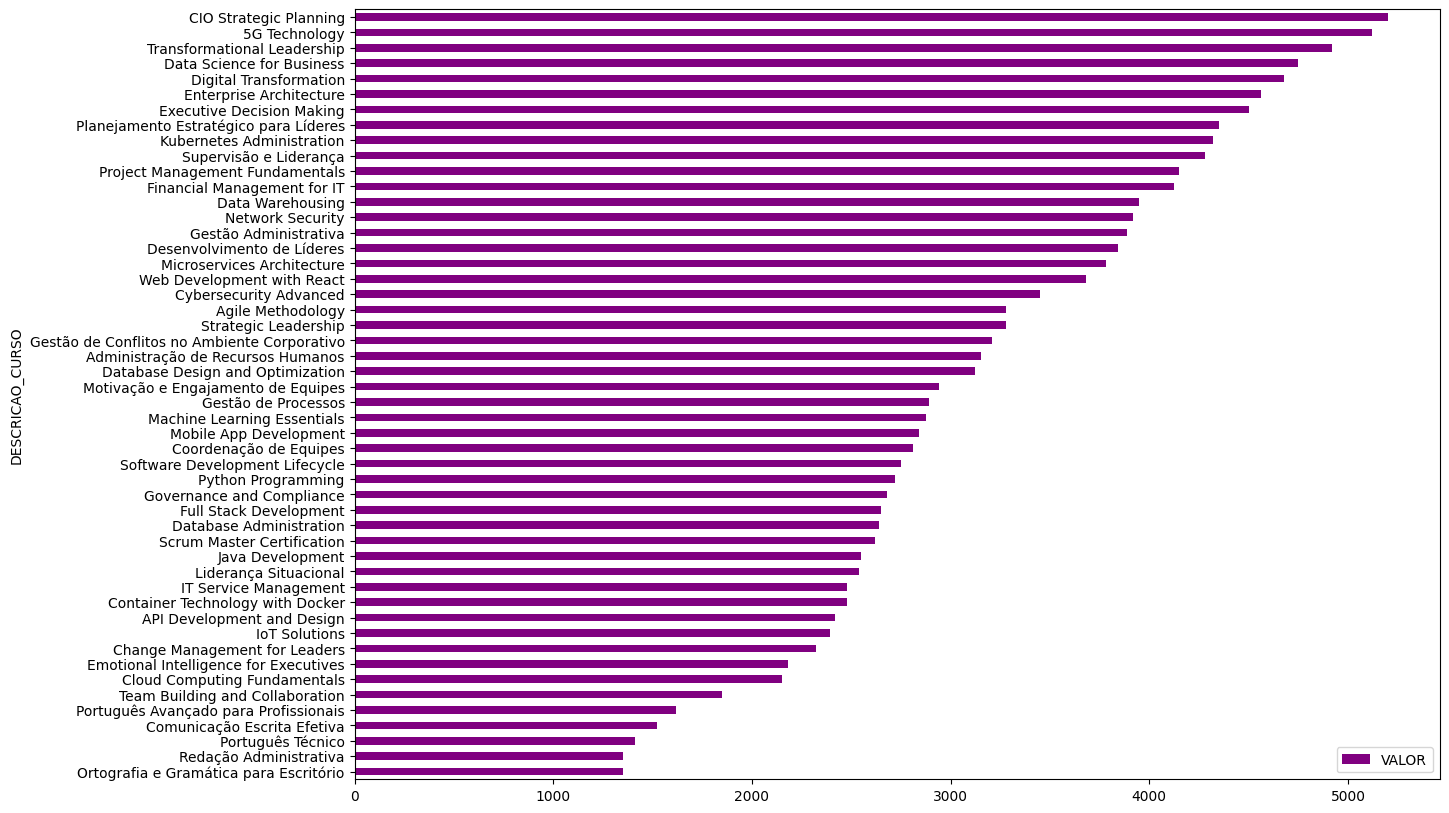

In [189]:
dados_curso_evento_valor = dados_curso.groupby('DESCRICAO_CURSO')[['VALOR']].mean().sort_values('VALOR')

dados_curso_evento_valor.plot(kind='barh', figsize=(14, 10), color ='purple');

## 3.4 BoxPlot para o Valores Contratados e Carga Horária

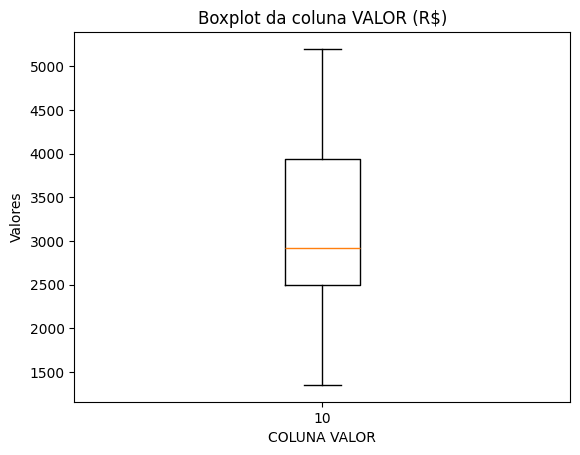

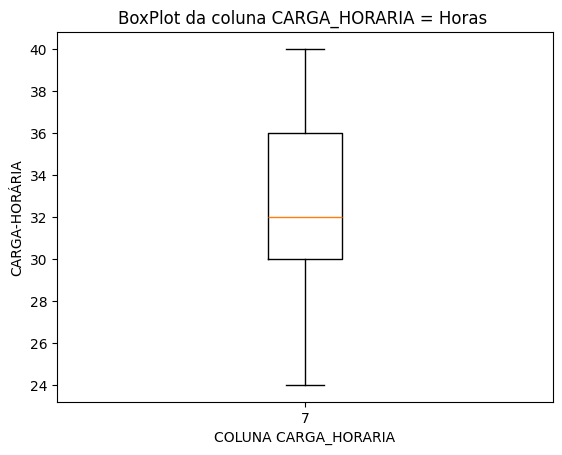

In [190]:
def gerarBoxplots(dados_curso):

    #BoxPlot para a Coluna VALOR CONTRATADO
    fig, ax = plt.subplots()
    ax.set_ylabel('VALOR')

    for n, col in enumerate(dados_curso.columns):
        if col == 'VALOR':
            ax.boxplot(dados_curso[col], positions=[n+1])

    plt.title('Boxplot da coluna VALOR (R$)')
    plt.ylabel('Valores')
    plt.xlabel("COLUNA VALOR")
    plt.show()

    print()

    #BoxPlot para a Coluna CARGA-HORÁRIA
    fig, ax = plt.subplots()
    ax.set_ylabel('CARGA_HORARIA')

    for n, col in enumerate(dados_curso.columns):
       if col == 'CARGA_HORARIA':
            ax.boxplot(dados_curso[col], positions=[n+1])

    plt.title("BoxPlot da coluna CARGA_HORARIA = Horas ")
    plt.ylabel("CARGA-HORÁRIA")
    plt.xlabel("COLUNA CARGA_HORARIA")
    plt.show()

gerarBoxplots(dados_curso)

## 3.5 Carga Horária média por modalidade

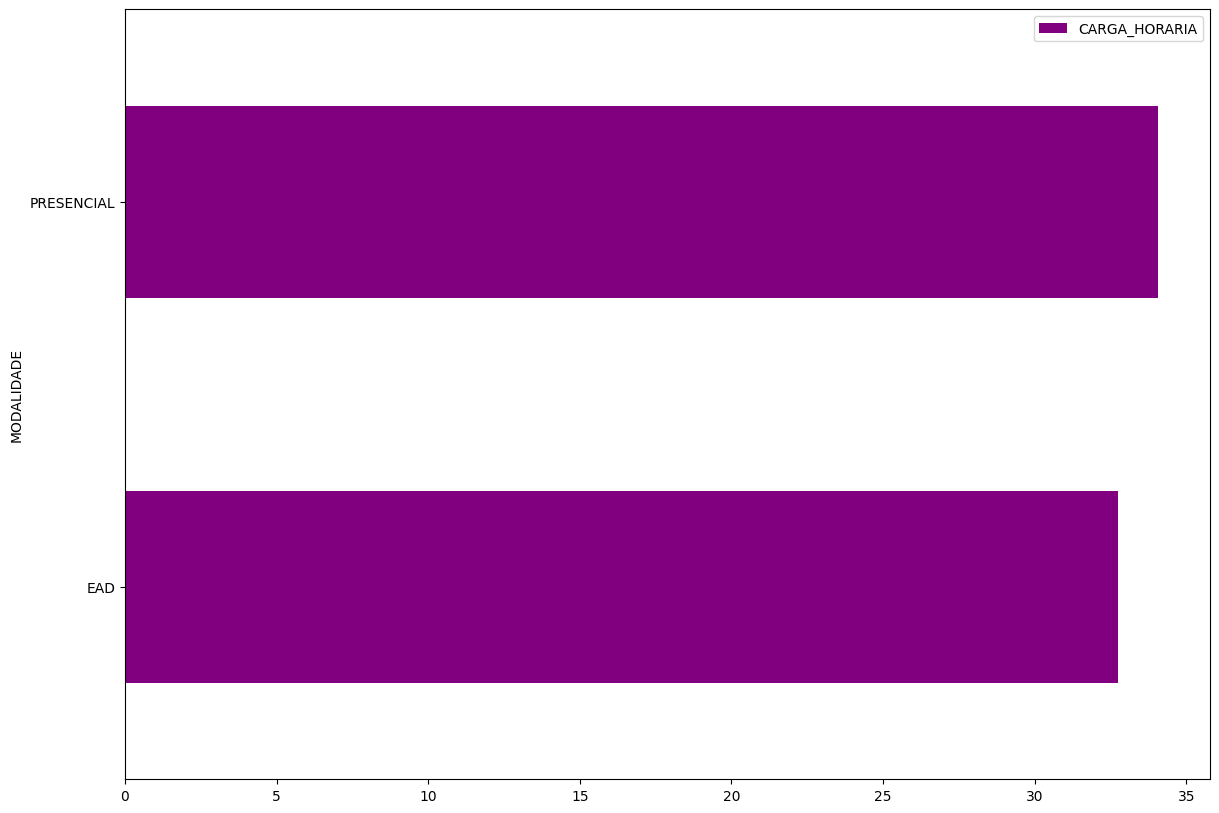

In [191]:
df_modalidade = dados_curso.groupby('MODALIDADE')[['CARGA_HORARIA']].mean().sort_values('CARGA_HORARIA')

df_modalidade.plot(kind='barh', figsize=(14, 10), color ='purple');

## 4. Validação da integridade entre as bases
Antes de exportar, vamos verificar se as referências entre as tabelas existem.

### 4.1 Participações sem funcionário correspondente

In [192]:
validar_funcionario = dados_participacaocurso[
    ~dados_participacaocurso["COD_MATRICULA"].isin(
        dados_funcionario["COD_MATRICULA"]
    )
]

print("Participações sem funcionário:")
display(validar_funcionario)

print("Total:", len(validar_funcionario))

Participações sem funcionário:


,COD_PROCESSO,COD_MATRICULA,NOME_FUNCIONARIO,CHEFE,DEPARTAMENTO,AREA,DESCRICAO_CURSO,PROGRAMA,FORMATO,MODALIDADE,DATA_INICIO,DATA_CONCLUSAO


Total: 0


## 4.2 Participações sem curso correspondente

In [193]:
validar_curso = dados_participacaocurso[
    ~dados_participacaocurso["COD_PROCESSO"].isin(
        dados_curso["COD_CURSO"]
    )
]

print("Participações sem curso correspondente:")
display(validar_curso)

print("Total:", len(validar_curso))

Participações sem curso correspondente:


,COD_PROCESSO,COD_MATRICULA,NOME_FUNCIONARIO,CHEFE,DEPARTAMENTO,AREA,DESCRICAO_CURSO,PROGRAMA,FORMATO,MODALIDADE,DATA_INICIO,DATA_CONCLUSAO


Total: 0


## 4.3 Participações com datas ausentes

In [207]:
sem_inicio = dados_participacaocurso["DATA_INICIO"].isna()

if sem_inicio.any():
    print("Sem início:", sem_inicio.sum())
    display(dados_participacaocurso[sem_inicio])


sem_conclusao = dados_participacaocurso["DATA_CONCLUSAO"].isna()

if sem_conclusao.any():
    print("Sem conclusão:", sem_conclusao.sum())
    display(dados_participacaocurso[sem_conclusao])

Sem conclusão: 3


,COD_PROCESSO,COD_MATRICULA,NOME_FUNCIONARIO,CHEFE,DEPARTAMENTO,AREA,DESCRICAO_CURSO,PROGRAMA,FORMATO,MODALIDADE,DATA_INICIO,DATA_CONCLUSAO
6,10024/2024,10073,Naomi Watts,Não,Departamento de Recursos Humanos,Administração,Gestão de Processos,Programa de Desenvolvimento de Líderes,INTERNO,EAD,2024-10-17,NaT
12,10020/2024,10065,<NA>,Não,Departamento de Recursos Humanos,Administração,Administração de Recursos Humanos,Programa de Desenvolvimento de Líderes,INTERNO,EAD,2024-07-10,NaT
15,10031/2025,10062,Bella Hadid,Não,Secretaria Acadêmica,Administração,Full Stack Development,Programa de Desenvolvimento de Sucessores,INTERNO,EAD,2025-07-08,NaT


## 4.4 Resumo geral da qualidade
Atenção: duas participações do mesmo funcionário no mesmo processo podem ser legítimas. Por isso, a contagem de duplicidades é apenas um alerta, não uma regra de exclusão.

In [218]:
def mostrar_duplicados_lado_a_lado(base, chaves):
    duplicados = base[
        base.duplicated(subset=chaves, keep=False)
    ].copy()

    if duplicados.empty:
        return

    duplicados = duplicados.sort_values(chaves)

    # Numera as ocorrências de cada grupo duplicado
    duplicados["_OCORRENCIA"] = (
        duplicados.groupby(chaves, dropna=False).cumcount() + 1
    )

    # Separa cada ocorrência em uma coluna
    resultado = duplicados.pivot(
        index=chaves,
        columns="_OCORRENCIA"
    )

    # Organiza os nomes das colunas
    resultado.columns = [
        f"{coluna}_REGISTRO_{ocorrencia}"
        for coluna, ocorrencia in resultado.columns
    ]

    display(resultado)

resumo_etl = pd.DataFrame({
    "Base": [
        "Curso",
        "Funcionário",
        "ParticipaçãoCurso"
    ],
    "Total de registros": [
        len(dados_curso),
        len(dados_funcionario),
        len(dados_participacaocurso)
    ],
    "Registros duplicados": [
        dados_curso.duplicated(["COD_CURSO"]).sum(),
        dados_funcionario.duplicated(["COD_MATRICULA"]).sum(),
        dados_participacaocurso.duplicated(
            ["COD_PROCESSO", "COD_MATRICULA"]
        ).sum()
    ]
})

display(resumo_etl)
print()

if dados_curso.duplicated(["COD_CURSO"]).any():
  print(">>> DUPLICADOS - CURSO")
  mostrar_duplicados_lado_a_lado(dados_curso, ["COD_CURSO"])

if dados_funcionario.duplicated(["COD_MATRICULA"]).any():
  print(">>> DUPLICADOS - FUNCIONÁRIO")
  mostrar_duplicados_lado_a_lado(dados_funcionario, ["COD_MATRICULA"])

if dados_participacaocurso.duplicated(["COD_PROCESSO", "COD_MATRICULA"]).any():
  print(">>> DUPLICADOS - PARTICIPAÇÃO CURSO")
  mostrar_duplicados_lado_a_lado(dados_participacaocurso, ["COD_PROCESSO", "COD_MATRICULA"])

,Base,Total de registros,Registros duplicados
0,Curso,50,0
1,Funcionário,140,0
2,ParticipaçãoCurso,2500,403



>>> DUPLICADOS - PARTICIPAÇÃO CURSO


NOME_FUNCIONARIO_REGISTRO_1  \
COD_PROCESSO COD_MATRICULA                               
10001/2024   10005                     Charlize Theron   
             10016                       Meghan Markle   
             10024                      Kendall Jenner   
             10029                     Ellen DeGeneres   
             10034                             Madonna   
...                                                ...   
10050/2026   10047                         Miley Cyrus   
             10059                         Alexa Chung   
             10075                      Cate Blanchett   
             10108                       Black Panther   
             10119                                João   

                           NOME_FUNCIONARIO_REGISTRO_2  \
COD_PROCESSO COD_MATRICULA                               
10001/2024   10005                     Charlize Theron   
             10016                       Meghan Markle   
             10024                      Kendall Jenner   
             10029                     Ellen DeGeneres   
             10034                             Madonna   
...                                                ...   
10050/2026   10047                         Miley Cyrus   
             10059                         Alexa Chung   
             10075                      Cate Blanchett   
             10108                       Black Panther   
             10119                                João   

                           NOME_FUNCIONARIO_REGISTRO_3  \
COD_PROCESSO COD_MATRICULA                               
10001/2024   10005                                <NA>   
             10016                                <NA>   
             10024                                <NA>   
             10029                                <NA>   
             10034                                <NA>   
...                                                ...   
10050/2026   10047                                <NA>   
             10059                                <NA>   
             10075                                <NA>   
             10108                                <NA>   
             10119                                <NA>   

                           NOME_FUNCIONARIO_REGISTRO_4 CHEFE_REGISTRO_1  \
COD_PROCESSO COD_MATRICULA                                                
10001/2024   10005                                <NA>              Sim   
             10016                                <NA>              Não   
             10024                                <NA>              Não   
             10029                                <NA>              Não   
             10034                                <NA>              Não   
...                                                ...              ...   
10050/2026   10047                                <NA>              Não   
             10059                                <NA>              Não   
             10075                                <NA>              Não   
             10108                                <NA>              Sim   
             10119                                <NA>              Não   

                           CHEFE_REGISTRO_2 CHEFE_REGISTRO_3 CHEFE_REGISTRO_4  \
COD_PROCESSO COD_MATRICULA                                                      
10001/2024   10005                      Sim             <NA>             <NA>   
             10016                      Não             <NA>             <NA>   
             10024                      Não             <NA>             <NA>   
             10029                      Não             <NA>             <NA>   
             10034                      Não             <NA>             <NA>   
...                                     ...              ...              ...   
10050/2026   10047                      Não             <NA>             <NA>   
             10059                      Não             <

## 5. Exportação dos dados limpos

In [196]:
# Exportação dos cursos
dados_curso.to_csv(
    "curso_limpo.csv",
    encoding="latin1",
    sep=";",
    index=False,
    date_format="%Y-%m-%d"
)

# Exportação dos funcionários
dados_funcionario.to_csv(
    "funcionario_limpo.csv",
    encoding="latin1",
    sep=";",
    index=False,
    date_format="%Y-%m-%d"
)

# Exportação das participações
dados_participacaocurso.to_csv(
    "participacaocurso_limpo.csv",
    encoding="latin1",
    sep=";",
    index=False,
    date_format="%Y-%m-%d"
)

print("Arquivos exportados com sucesso!")
mostrar_bases()

Arquivos exportados com sucesso!
(50, 10)


,COD_CURSO,DESCRICAO_CURSO,PROGRAMA,CATEGORIA,FORMATO,DATA_INCLUSAO,CARGA_HORARIA,MODALIDADE,CURSO_REALIZADO,VALOR
0,10001/2024,Cloud Computing Fundamentals,Programa de Desenvolvimento de Sucessores,TÉCNICO,INTERNO,2024-07-07,40,EAD,Sim,2150.75
1,10002/2024,Cybersecurity Advanced,Programa de Desenvolvimento de Sucessores,TÉCNICO,EXTERNO,2024-06-27,32,PRESENCIAL,Sim,3450.5
2,10003/2024,Machine Learning Essentials,Programa de Desenvolvimento de Sucessores,TÉCNICO,INTERNO,2024-10-16,36,EAD,Sim,2875.25
3,10004/2024,Português Avançado para Profissionais,Programa de Desenvolvimento de Líderes,PESSOAL,INTERNO,2024-02-20,30,PRESENCIAL,Sim,1620.0
4,10005/2024,Redação Administrativa,Programa de Desenvolvimento de Líderes,PESSOAL,INTERNO,2024-05-20,28,EAD,Não,1350.9


(140, 10)


,COD_MATRICULA,NOME_FUNCIONARIO,MATRICULA_ATIVA,CARGO,AREA,CHEFE,DEPARTAMENTO,SEXO,GRAU_INSTRUCAO,DATA_NASCIMENTO
0,10001,Jennifer Lopez,<NA>,Professor,Acadêmico,Não,Coordenação de Análise e Desenvolvimento de Si...,F,Pós-Graduado,1969-07-24
1,10002,Isabela Fontana,Sim,Instrutor,Acadêmico,Não,Coordenação de Banco de Dados,F,Graduado,1982-07-20
2,10003,Paolla Oliveira,Sim,Auxiliar Administrativo,Administração,Não,Secretaria Acadêmica,F,Graduado,1982-08-05
3,10004,Ana Hickman,Não,Secretário,Administração,Não,Secretaria Acadêmica,F,Graduado,1971-03-01
4,10005,Charlize Theron,Sim,Professor,Acadêmico,Sim,Coordenação de Análise e Desenvolvimento de Si...,F,Mestrado,1975-08-07


(2500, 12)


,COD_PROCESSO,COD_MATRICULA,NOME_FUNCIONARIO,CHEFE,DEPARTAMENTO,AREA,DESCRICAO_CURSO,PROGRAMA,FORMATO,MODALIDADE,DATA_INICIO,DATA_CONCLUSAO
0,10002/2024,10070,Linda Evangelista,Não,Secretaria Acadêmica,Administração,Cybersecurity Advanced,Programa de Desenvolvimento de Sucessores,EXTERNO,PRESENCIAL,2024-01-19,2024-01-23
1,10010/2024,10012,Gal Gadot,Não,Coordenação de Análise e Desenvolvimento de Si...,Acadêmico,Liderança Situacional,Programa de Desenvolvimento de Líderes,INTERNO,EAD,2024-08-13,2024-08-17
2,10046/2025,10006,Kate Beckinsale,Não,Coordenação de Banco de Dados,Acadêmico,Agile Methodology,Programa de Desenvolvimento de Sucessores,EXTERNO,<NA>,2025-09-19,2025-09-23
3,10048/2025,10130,Timóteo,Não,Departamento de Recursos Humanos,Recursos Humanos,Project Management Fundamentals,Programa de Desenvolvimento de Sucessores,EXTERNO,PRESENCIAL,2025-03-02,2025-03-07
4,10043/2025,10070,Linda Evangelista,Não,Secretaria Acadêmica,Administração,<NA>,Programa de Desenvolvimento de Sucessores,INTERNO,EAD,2025-08-27,2025-08-31
